## Import modules

In [1]:
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets
from matplotlib import pyplot as plt
from IPython.display import display, clear_output
import numpy as np

# TD 1. Spin lattices

Let us consider an $L$x$L$ lattice of discrete variables (spins=-1 or +1)

1. Run the following code, which contains methods to
    - convert spin indices (i,j) into a global index n=L*i+j
    - display and interact with spin lattices

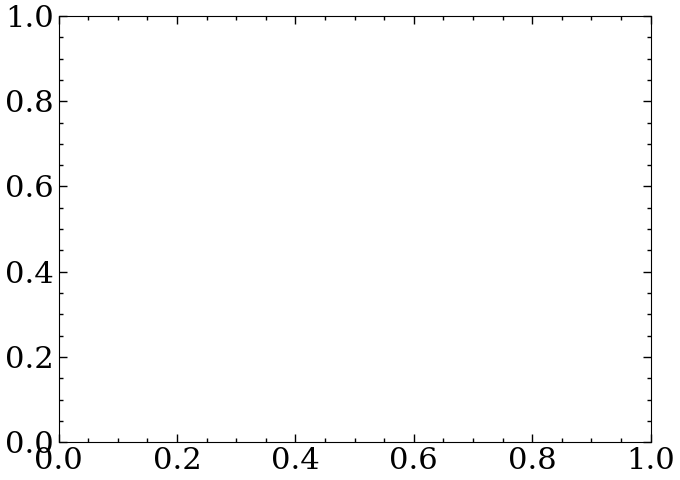

In [2]:
rng = np.random.default_rng(12345)

# Conversion between indices
def get_ij(n,L):
    return (n//L,n%L)
def get_n(i,j,L):
    return L*i+j
    
    
# Representation

def getButtons(L, LatticeOutput, GraphOutput=None):
    global spins, Js
    # Generates the spins as an array of Buttons (widgets) on which one can click
    buttons= np.ndarray( (2*L-1,2*L-1), dtype= widgets.Button)
    button_layout = widgets.Layout(height='30px', width='35px')
    emptyButton= widgets.Button(layout= button_layout, description=" ", style={'button_color': 'white'} )
    
    for twoi in range(2*L-1):
        for twoj in range(2*L-1):
            i= twoi//2
            j= twoj//2
            m= get_n( i,j,L )
            if twoj%2==0:
                # spin row
                if twoi%2==0:
                    # this is a node
                    buttons[twoj,twoi]= widgets.Button(layout= button_layout, description="%i"%m, style={'button_color': 'yellow' if spins[m]==1 else 'cyan'} )
                else:
                    # this is a horizontal link
                    n= get_n( i+1,j,L )
                    mybool= bool(Js[(m,n)]==1)
                    buttons[twoj,twoi]= widgets.Button(layout= button_layout, description="+" if mybool else "--", style={'button_color': 'white','text_color': 'green' if mybool else 'red'} )
            else:
                # link row 
                if twoi%2==0:
                    # this is a vertical link
                    n= get_n( i,j+1,L )
                    mybool= bool(Js[(m,n)]==1)
                    buttons[twoj,twoi]= widgets.Button(layout= button_layout, description="+" if mybool else "|", style={'button_color': 'white','text_color': 'green' if mybool else 'red'} )
                else:
                    buttons[twoj,twoi]= emptyButton
                    
    def on_button_clicked(b):
        global spins
        m= int(b.description)
        (i,j)= get_ij(m,L)
        spins[m]*=-1
        if GraphOutput:
            updateEnergyGraph(GraphOutput)
        with LatticeOutput:
            #b.description = '%i'%(m)
            b.style.button_color = 'yellow' if spins[m]==1 else 'cyan'
        
    for i in range(L):
        for j in range(L):
            buttons[2*j,2*i].on_click(on_button_clicked)
    return buttons



def getLattice(L,LatticeOutput,GraphOutput=None):
    # Generates a lattice of regularly aligned spin Buttons, separated by link Buttons
    buttons= getButtons(L,LatticeOutput,GraphOutput)
    box_layout = widgets.Layout(overflow='scroll hidden',
                    border='0px solid black',
                    width='350px',
                    height='',
                    flex_flow='row',
                    align_items = 'center',
                    display='flex')

    SpinRow= [ [] for cpt in range(2*L-1) ]
    for twoj in range(2*L-1):
        SpinRow[twoj] = widgets.Box(children= list(buttons[twoj,:]), layout=box_layout)  
        
    return widgets.VBox(SpinRow), buttons

def showLattice(L):
    LatticeOutput=  widgets.Output(layout=widgets.Layout(height='5cm', width = '7cm', border='0px'))
    Lattice, buttons= getLattice(L,LatticeOutput)
    display(Lattice)
    
plt.ioff()
figEnergies= plt.figure( figsize=(7,5));
axEnergies= figEnergies.subplots(1);

def updateEnergyGraph(GraphOutput):
    if len(axEnergies.lines)>0:
        energies= list(axEnergies.lines[0].get_ydata())
    else:
        energies= list([])
    axEnergies.clear()
    axEnergies.set_ylabel("Energy")
    axEnergies.set_xlim(0,100)
    axEnergies.set_ylim(-50,50)
    E= getEnergy(spins,Js)
    energies.append(E)
    axEnergies.plot( energies, 'bo')
    with GraphOutput:
        clear_output(wait=True)
        display(axEnergies.figure)
        

def showLatticeandGraph(L):
    global axEnergies
    axEnergies.clear()
    LatticeOutput=  widgets.Output(layout=widgets.Layout(height='7cm', width = '7cm', border='0px'))
    GraphOutput=  widgets.Output(layout=widgets.Layout(height='5cm', width = '7cm', border='0px'))
    Lattice, buttons= getLattice(L,LatticeOutput,GraphOutput)
    updateEnergyGraph(GraphOutput)
    Hbox_layout = widgets.Layout(
                    border='0px solid black',
                    width='800px',
                    height='',
                    flex_flow='row',
                    align_items = 'center',
                    display='flex')
    
    twopack= widgets.HBox([Lattice,GraphOutput], layout=Hbox_layout)
    display(twopack)
    return buttons


2. Read and edit the following code to set
   - the linear size $L$ of the lattice
   - the initial values of the spins
   - the initial values of the coupling constants $J$
   - -----     
   Execute the command and check that you can flip the spins by clicking on them (yellow=+1; blue=-1)

In [3]:
# Linear size of the lattice
L= ?? ## 6

# The spins (i,j) are a dictionary with entries ("keys") labeled NOT by (i,j), but by their global 1-D index n=L*i+j
# Define the initial values of the spins (-1 or +1)
spins= {}
for n in range(L*L):
        spins[n]= ?? ## 1

# The coupling constants J are a dictionary with entries ("keys") labeled by (m,n), where m is the global index of the first node and n>m the global index of the second node
# The initial values of the spins are randomly set to +1
Js= {}
for m in range(L*L):
    (i,j)= get_ij(m,L) # get the "i" and "j" coordinates of the spin on the lattice
    # Create a link to the right of (i,j) if suitable
    if i<L-1:
        n= get_n( i+1,j,L )
        Js[(m,n)]= 1
    # Create a link underneath (i,j) if suitable
    if j<L-1:
        n= get_n( i,j+1,L )
        Js[(m,n)]= 1

# Display a clickable lattice
showLattice(L)


3. Define the total energy of the spin lattice, as a function of the spin values (spins dictionary) and coupling constants (J dictionary).
   Check that it evolves as expected, when you click on the spins to flip them.

In [4]:
def getEnergy(spins,Js):
    ##return ??
    E= 0.
    for (m,n),J in Js.items():
        E+= -J*spins[m]*spins[n]
    return E


showLatticeandGraph(L);

4. Define how the spins change at each time step.
   Hint: Use Glauber dynamics, i.e.,
   - calculate the energy E1 of the system
   - randomly select a spin
   - calculate its hypothetical energy E2 if this spin were flipped
   - actually flip it if E2<E1. Otherwise, flip it with probability exp( -(E2-E1)/Temperature )
   - ----------
   Comment on the final state of the system depending on the temperature.

In [5]:
def flipSpin(n,buttons):
    (i,j)= get_ij(n,L)
    buttons[2*j,2*i].click()
    
def GlauberStep(Temperature,buttons):
    global spins
    # Select a random spin
    m= int(L*L*rng.random())
    """
    # 
    (...)
    #
    if ??:
        spins[m] *=-1 # flip the spin
    """
    E1= getEnergy(spins,Js)
    spins[m]*=-1
    E2= getEnergy(spins,Js)
    if E2<E1:
        spins[m]*=-1
        flipSpin(m,buttons)
        return
    if rng.random()< np.exp ( (E1-E2)/Temperature):
        spins[m]*=-1
        flipSpin(m,buttons)
        return
    spins[m]*=-1  # come back to initial state

buttons= showLatticeandGraph(L)
import time
Temperature= 0.5
for t in range(200):
    GlauberStep(Temperature,buttons)
    time.sleep(0.01)

## Spin glasses

5. Now, instead of a homogeneous system, generate a splin glass by randomly assigning +1 or -1 values to the spins.
   How does the energy change with time? Comment.

In [6]:
# The coupling constants J are a dictionary with entries ("keys") labeled by (m,n), where m is the global index of the first node and n>m the global index of the second node
# The initial values of the spins are randomly set to +1 or -1
# rng.random() is a random number between 0 and 1

Js= {}
for m in range(L*L):
    (i,j)= get_ij(m,L) # get the "i" and "j" coordinates of the spin on the lattice
    # Create a link to the right of (i,j) if suitable
    if i<L-1:
        n= get_n( i+1,j,L )
        Js[(m,n)]= 1 if rng.random()<0.5 else -1 ##??
    # Create a link underneath (i,j) if suitable
    if j<L-1:
        n= get_n( i,j+1,L )
        Js[(m,n)]= 1 if rng.random()<0.5 else -1 ##??
        
showLattice(L)

6. Run Glauber dynamics on this spin glass.

In [8]:
buttons= showLatticeandGraph(L)
Temperature= 0.5
for t in range(200):
    GlauberStep(Temperature,buttons)
    time.sleep(0.01)

## Hopfield network

   Instead of changing spins to reduce the energy, we now set to adjust the coupling coefficients J so that the energy is minimised.
   The motivation is as follows: Consider the initial spin configuration as an input "image". The network will try to learn it it in its "flesh", i.e., its coupling coefficients. When another input is given, minimising the energy of the input will lead to the learnt image.
   We will now work with fully connected networks, instead of only connecting adjacent spins.

7. For a given input "image" (spin configuration), set the coupling coefficients J so that the energy is minised.

In [9]:
# Generate a "random" input image
spins= {}
liste= [7,8,13,14,25,26,31,32,21,10,17,23,29,34]
for n in range(L*L):
        spins[n]= +1 #
for n in liste:
        spins[n]=-1 #if rng.random()<0.5 else 1

# Set the coupling coefficients of the fully connected network to minimise the energy
def get_optimal_J(spins_loc):
    Js_loc= {}
    for n1 in range(L*L):
        (i1,j1)= get_ij(n1,L)
        for n2 in range(n1+1,L*L):
            (i2,j2)= get_ij(n2,L) # get the "i" and "j" coordinates of the spin on the lattice
            Js_loc[(n1,n2)]= spins[n1]*spins[n2]
    return Js_loc

Js= get_optimal_J(spins)
# Display the lattice
# NB: of course, not all links J will be shown!
showLattice(L)

8. Check that, if you start with another random picture, the dynamics (e.g., low-temperature Glauber dynamics) converge to the image stored in memory.
NB: If you are unlucky and get the negative, comment on this result.

In [40]:
# Generate another random input image
spins= {}
for n in range(L*L):
        spins[n]= -1 if rng.random()<0.5 else 1

# Evolve the system starting from this new configuration
buttons= showLatticeandGraph(L)

Temperature= 0.1
for t in range(200):
    GlauberStep(Temperature,buttons)
    time.sleep(0.01)


9. Let us now try to store several images, e.g., the images of the numbers "0", "1", "2" and "3".
   How would you set the coupling coefficients to try to remember these four images?

In [60]:
# Generate another random input image
spins0123= [{} for cpt in range(4)] # spins0123[0]=>0 spins0123[1]=>1 etc.
listes= [ [13,19,25,26,27,28,22,16,15,14], #0
          [14,19,20,21,22], #1
          [13,19,25,26,27,21,15,16,17,23,29], #2
          [13,19,25,26,27,21,15,28,29,23,17] ] #3
for cpt in range(4):
    for n in range(L*L):
            spins0123[cpt][n]= +1 
    for n in listes[cpt]:
            spins0123[cpt][n]=-1 

# Define suitable coefficients
Js0123= [{} for cpt in range(4)]
for cpt in range(4):
    Js0123[cpt]= get_optimal_J(spins0123[cpt])

for m in range(L*L):
    for n in range(m+1,L*L):
        Js[(m,n)] = 0.25* np.sum( [Js0123[cpt][(m,n)] for cpt in range(4)] )

spins= {}
for n in range(L*L):
        spins[n]= -1 if rng.random()<0.5 else 1

# Evolve the system starting from this new configuration
buttons= showLatticeandGraph(L)

Temperature= 0.05
for t in range(200):
    GlauberStep(Temperature,buttons)
    time.sleep(0.01)


10. Suppose that, instead of spins $\sigma$∈{-1,+1}, one used spins $\sigma$∈{0,+1}. Would this impact the memory capacity of the network? How many images could such a spin network precisely 'memorise'?